# DataCo Supply Chain - Dự đoán giao hàng trễ (Submission 2)

**Bài toán:** Binary classification - dự đoán đơn hàng có bị giao trễ hay không (`Late_delivery_risk`: 1 = trễ, 0 = không trễ).

**Nội dung notebook:**
1. Đọc dữ liệu
2. Tìm hiểu tổng quan dữ liệu (kích thước, kiểu dữ liệu, missing, trùng lặp)
3. Chọn biến mục tiêu (target)
4. Kiểm tra rò rỉ dữ liệu (data leakage)
5. EDA - Vận chuyển
6. EDA - Địa lý
7. EDA - Sản phẩm và khách hàng
8. EDA - Biến số và tương quan
9. Tiền xử lý dữ liệu (chọn cột, encoding)
10. Tổng kết

*Ghi chú: phần EDA theo thời gian (order date) tạm thời chưa đưa vào, sẽ nghiên cứu và bổ sung sau.*

## 0. Import thư viện

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')

# tạo thư mục để lưu hình
if not os.path.exists('figures_s2'):
    os.makedirs('figures_s2')
if not os.path.exists('results_s2'):
    os.makedirs('results_s2')

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', 100)
print('Import xong!')

Import xong!


## 1. Đọc dữ liệu

In [2]:
# file csv bị lỗi font nếu đọc utf-8 nên mình dùng encoding latin-1
df = pd.read_csv('DataCoSupplyChainDataset.csv', encoding='latin-1')
print('Đọc dữ liệu thành công')

Đọc dữ liệu thành công


In [3]:
df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,1/13/2018 11:45,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,1/13/2018 11:24,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [4]:
# đọc thêm file mô tả các cột
desc = pd.read_csv('DescriptionDataCoSupplyChain.csv')
desc

,FIELDS,DESCRIPTION
0,Type,: Type of transaction made
1,Days for shipping (real),: Actual shipping days of the purchased product
2,Days for shipment (scheduled),: Days of scheduled delivery of the purchased...
3,Benefit per order,: Earnings per order placed
4,Sales per customer,: Total sales per customer made per customer
5,Delivery Status,: Delivery status of orders: Advance shipping...
6,Late_delivery_risk,: Categorical variable that indicates if send...
7,Category Id,: Product category code
8,Category Name,: Description of the product category
9,Customer City,: City where the customer made the purchase


## 2. Tổng quan dữ liệu

In [5]:
print('Số dòng:', df.shape[0])
print('Số cột:', df.shape[1])

Số dòng: 180519
Số cột: 53


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Email                 180519 non-null  object 
 12  Customer Fname                

In [7]:
# đếm số cột theo kiểu dữ liệu
print(df.dtypes.value_counts())

object     24
float64    15
int64      14
Name: count, dtype: int64


In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Days for shipping (real),180519.0,3.497654,1.623722,0.000000,2.000000,3.000000,5.000000,6.000000
Days for shipment (scheduled),180519.0,2.931847,1.374449,0.000000,2.000000,4.000000,4.000000,4.000000
Benefit per order,180519.0,21.974989,104.433526,-4274.979980,7.000000,31.520000,64.800003,911.799988
Sales per customer,180519.0,183.107609,120.043670,7.490000,104.379997,163.990005,247.399994,1939.989990
Late_delivery_risk,180519.0,0.548291,0.497664,0.000000,0.000000,1.000000,1.000000,1.000000
Category Id,180519.0,31.851451,15.640064,2.000000,18.000000,29.000000,45.000000,76.000000
Customer Id,180519.0,6691.379495,4162.918106,1.000000,3258.500000,6457.000000,9779.000000,20757.000000
Customer Zipcode,180516.0,35921.126914,37542.461122,603.000000,725.000000,19380.000000,78207.000000,99205.000000
Department Id,180519.0,5.443460,1.629246,2.000000,4.000000,5.000000,7.000000,12.000000
Latitude,180519.0,29.719955,9.813646,-33.937553,18.265432,33.144863,39.279617,48.781933


In [9]:
# khoảng thời gian của dữ liệu
ngay_dat = pd.to_datetime(df['order date (DateOrders)'], format='%m/%d/%Y %H:%M')
print('Ngày đặt hàng sớm nhất:', ngay_dat.min())
print('Ngày đặt hàng muộn nhất:', ngay_dat.max())

Ngày đặt hàng sớm nhất: 2015-01-01 00:00:00
Ngày đặt hàng muộn nhất: 2018-01-31 23:38:00


### 2.1 Kiểm tra giá trị thiếu (missing)

In [10]:
missing = df.isnull().sum()
missing_percent = df.isnull().sum() / len(df) * 100
missing_df = pd.DataFrame({'so_luong_missing': missing, 'phan_tram': missing_percent})
missing_df = missing_df[missing_df['so_luong_missing'] > 0]
missing_df = missing_df.sort_values('phan_tram', ascending=False)
print(missing_df)

                     so_luong_missing   phan_tram
Product Description            180519  100.000000
Order Zipcode                  155679   86.239676
Customer Lname                      8    0.004432
Customer Zipcode                    3    0.001662


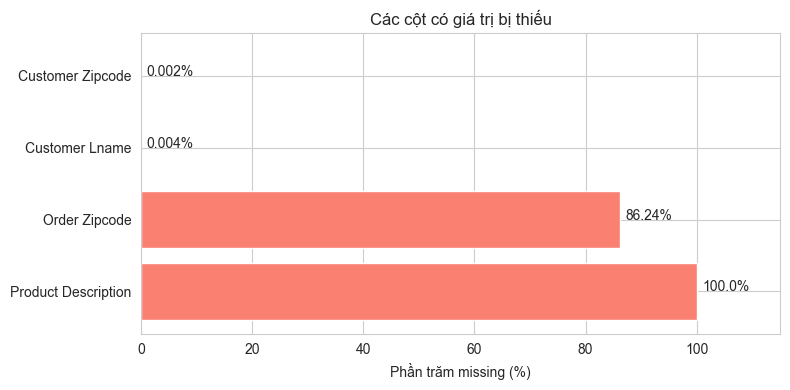

In [11]:
plt.figure(figsize=(8, 4))
plt.barh(missing_df.index, missing_df['phan_tram'], color='salmon')
plt.xlabel('Phần trăm missing (%)')
plt.title('Các cột có giá trị bị thiếu')
for i in range(len(missing_df)):
    plt.text(missing_df['phan_tram'].iloc[i] + 1, i, str(round(missing_df['phan_tram'].iloc[i], 3)) + '%')
plt.xlim(0, 115)
plt.tight_layout()
plt.savefig('figures_s2/fig01_missing.png')
plt.show()

**Nhận xét:** `Product Description` bị thiếu 100% và `Order Zipcode` thiếu khoảng 86% nên sẽ bỏ 2 cột này. `Customer Lname` (8 dòng) và `Customer Zipcode` (3 dòng) thiếu rất ít và mình cũng không dùng 2 cột này để train.

### 2.2 Kiểm tra dòng trùng lặp và số giá trị khác nhau

In [12]:
print('Số dòng trùng lặp:', df.duplicated().sum())
print('Số Order Item Id khác nhau:', df['Order Item Id'].nunique())
print('Số Order Id khác nhau:', df['Order Id'].nunique())

Số dòng trùng lặp: 0
Số Order Item Id khác nhau: 180519
Số Order Id khác nhau: 65752


Mỗi dòng là một **item trong đơn hàng** (Order Item Id là duy nhất), một đơn (Order Id) có thể có nhiều dòng.

In [13]:
# số giá trị khác nhau của từng cột
nunique = df.nunique().sort_values()
print(nunique)

Product Description                   0
Product Status                        1
Customer Password                     1
Customer Email                        1
Late_delivery_risk                    2
Customer Country                      2
Customer Segment                      3
Type                                  4
Shipping Mode                         4
Delivery Status                       4
Days for shipment (scheduled)         4
Order Item Quantity                   5
Market                                5
Days for shipping (real)              7
Order Status                          9
Department Id                        11
Department Name                      11
Order Item Discount Rate             18
Order Region                         23
Customer State                       46
Category Name                        50
Category Id                          51
Product Category Id                  51
Product Price                        75
Order Item Product Price             75


In [14]:
# những cột chỉ có 1 giá trị thì không có ích cho mô hình
for col in df.columns:
    if df[col].nunique() <= 1:
        print(col, '-> chỉ có', df[col].nunique(), 'giá trị:', df[col].unique()[:3])

Customer Email -> chỉ có 1 giá trị: ['XXXXXXXXX']
Customer Password -> chỉ có 1 giá trị: ['XXXXXXXXX']
Product Description -> chỉ có 0 giá trị: [nan]


Product Status -> chỉ có 1 giá trị: [0]


In [15]:
# các cột thông tin cá nhân bị che
print(df['Customer Email'].unique()[:5])
print(df['Customer Password'].unique()[:5])

['XXXXXXXXX']
['XXXXXXXXX']


## 3. Chọn biến mục tiêu (target)

In [16]:
print(df['Late_delivery_risk'].value_counts())
print()
print(df['Late_delivery_risk'].value_counts(normalize=True) * 100)

Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64

Late_delivery_risk
1    54.829132
0    45.170868
Name: proportion, dtype: float64


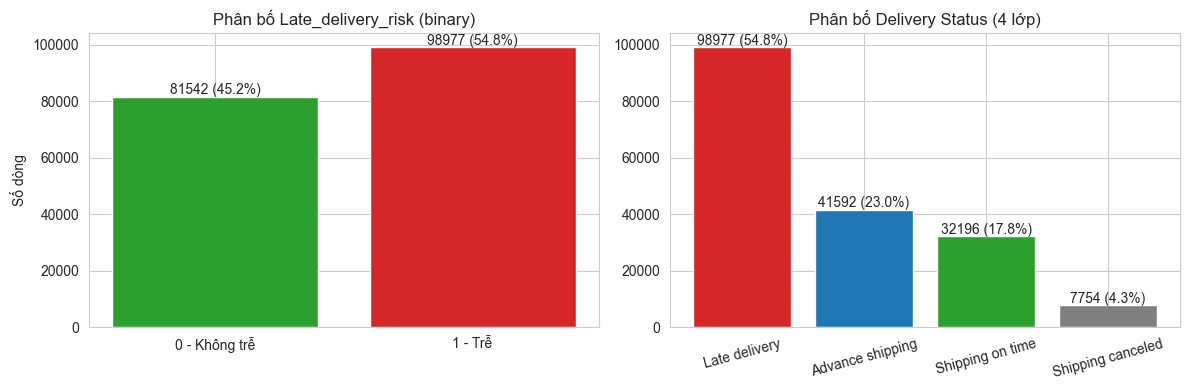

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

counts = df['Late_delivery_risk'].value_counts().sort_index()
ax[0].bar(['0 - Không trễ', '1 - Trễ'], counts.values, color=['tab:green', 'tab:red'])
for i in range(len(counts)):
    ax[0].text(i, counts.values[i] + 1000, str(counts.values[i]) + ' (' + str(round(counts.values[i] / len(df) * 100, 1)) + '%)', ha='center')
ax[0].set_title('Phân bố Late_delivery_risk (binary)')
ax[0].set_ylabel('Số dòng')

counts2 = df['Delivery Status'].value_counts()
ax[1].bar(counts2.index, counts2.values, color=['tab:red', 'tab:blue', 'tab:green', 'tab:gray'])
for i in range(len(counts2)):
    ax[1].text(i, counts2.values[i] + 1000, str(counts2.values[i]) + ' (' + str(round(counts2.values[i] / len(df) * 100, 1)) + '%)', ha='center')
ax[1].set_title('Phân bố Delivery Status (4 lớp)')
ax[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig('figures_s2/fig02_target.png')
plt.show()

In [18]:
# xem thử Order Status
print(df['Order Status'].value_counts())
print()
print(df['Order Status'].value_counts(normalize=True) * 100)

Order Status
COMPLETE           59491
PENDING_PAYMENT    39832
PROCESSING         21902
PENDING            20227
CLOSED             19616
ON_HOLD             9804
SUSPECTED_FRAUD     4062
CANCELED            3692
PAYMENT_REVIEW      1893
Name: count, dtype: int64

Order Status
COMPLETE           32.955534
PENDING_PAYMENT    22.065267
PROCESSING         12.132795
PENDING            11.204915
CLOSED             10.866446
ON_HOLD             5.431007
SUSPECTED_FRAUD     2.250179
CANCELED            2.045214
PAYMENT_REVIEW      1.048643
Name: proportion, dtype: float64


**Nhận xét:**
- `Late_delivery_risk` có tỉ lệ 54.8% / 45.2% -> khá cân bằng, phù hợp làm **binary classification**.
- `Delivery Status` có 4 lớp, lớp `Shipping canceled` chỉ 4.3% -> có thể làm multiclass sau.
- `Order Status` có 9 lớp, mất cân bằng nhiều và là trạng thái xử lý đơn (không phải giao hàng) -> không chọn làm target.

=> **Chọn target là `Late_delivery_risk`.**

*Số liệu ở mục này tính trên dữ liệu gốc, trước khi bỏ đơn hủy ở mục 4b.*

## 4. Kiểm tra rò rỉ dữ liệu (data leakage)

Rò rỉ dữ liệu là khi feature chứa thông tin chỉ biết **sau khi** đã giao hàng. Nếu dùng thì mô hình sẽ "gian lận" và có độ chính xác ảo.

In [19]:
# so sánh Delivery Status với target
ct = pd.crosstab(df['Delivery Status'], df['Late_delivery_risk'])
print(ct)

Late_delivery_risk      0      1
Delivery Status                 
Advance shipping    41592      0
Late delivery           0  98977
Shipping canceled    7754      0
Shipping on time    32196      0


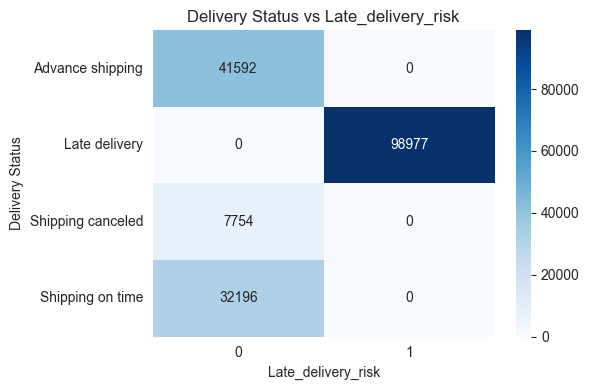

In [20]:
plt.figure(figsize=(6, 4))
sns.heatmap(ct, annot=True, fmt='d', cmap='Blues')
plt.title('Delivery Status vs Late_delivery_risk')
plt.tight_layout()
plt.savefig('figures_s2/fig03_leak_delivery_status.png')
plt.show()

In [21]:
# nếu số ngày giao thực tế > số ngày dự kiến thì có phải là trễ không?
df['tre_theo_luat'] = (df['Days for shipping (real)'] > df['Days for shipment (scheduled)']).astype(int)
dung = (df['tre_theo_luat'] == df['Late_delivery_risk']).sum()
print('Số dòng khớp:', dung, '/', len(df))
print('Tỉ lệ khớp:', round(dung / len(df) * 100, 2), '%')

Số dòng khớp: 176096 / 180519
Tỉ lệ khớp: 97.55 %


In [22]:
# xem những dòng không khớp là gì
khong_khop = df[df['tre_theo_luat'] != df['Late_delivery_risk']]
print(khong_khop['Delivery Status'].value_counts())

Delivery Status
Shipping canceled    4423
Name: count, dtype: int64


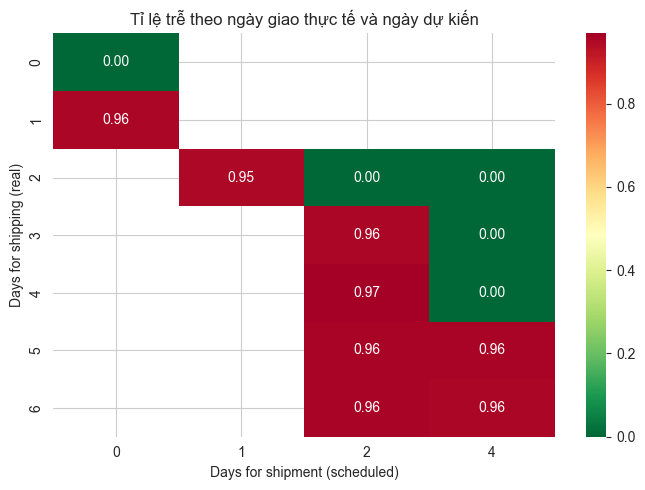

In [23]:
# vẽ heatmap tỉ lệ trễ theo số ngày thực tế và số ngày dự kiến
pivot = df.pivot_table(index='Days for shipping (real)', columns='Days for shipment (scheduled)', values='Late_delivery_risk', aggfunc='mean')
plt.figure(figsize=(7, 5))
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='RdYlGn_r')
plt.title('Tỉ lệ trễ theo ngày giao thực tế và ngày dự kiến')
plt.tight_layout()
plt.savefig('figures_s2/fig04_leak_real_vs_scheduled.png')
plt.show()

In [24]:
# Order Status: các đơn bị hủy / nghi gian lận thì Delivery Status là gì?
ct2 = pd.crosstab(df['Order Status'], df['Delivery Status'])
print(ct2)

Delivery Status  Advance shipping  Late delivery  Shipping canceled  \
Order Status                                                          
CANCELED                        0              0               3692   
CLOSED                       4809          11109                  0   
COMPLETE                    14136          34199                  0   
ON_HOLD                      2413           5450                  0   
PAYMENT_REVIEW                420           1082                  0   
PENDING                      4857          11712                  0   
PENDING_PAYMENT              9588          22922                  0   
PROCESSING                   5369          12503                  0   
SUSPECTED_FRAUD                 0              0               4062   

Delivery Status  Shipping on time  
Order Status                       
CANCELED                        0  
CLOSED                       3698  
COMPLETE                    11156  
ON_HOLD                      1941  
PA

**Nhận xét:**
- `Delivery Status = Late delivery` <=> `Late_delivery_risk = 1` (trùng 100%).
- Chỉ cần luật `real > scheduled` đã đúng ~97.5% (những dòng không khớp đều là đơn bị hủy).
- `Order Status` CANCELED/SUSPECTED_FRAUD <=> `Shipping canceled`, cũng là thông tin sau khi xử lý đơn.

=> Phải **bỏ** các cột: `Delivery Status`, `Days for shipping (real)`, `shipping date (DateOrders)`, `Order Status`.

*Số liệu ở mục này tính trên dữ liệu gốc, trước khi bỏ đơn hủy ở mục 4b.*

In [25]:
df = df.drop(columns=['tre_theo_luat'])

## 4b. Data Cleaning: Bỏ đơn huỷ

**Vì sao bỏ đơn hủy?** Đơn hủy đang mang nhãn `Late_delivery_risk = 0`, giống đơn giao đúng hoặc trước hạn. Nhưng các đơn này chưa từng được giao, nên nhãn 0 không có nghĩa là "không trễ". Sau bước này, mô hình chỉ áp dụng cho đơn không bị hủy.

In [26]:
# kiểm tra: mỗi đơn có bao nhiêu nhãn và bao nhiêu trạng thái khác nhau?
so_nhan = df.groupby('Order Id')['Late_delivery_risk'].nunique()
so_trang_thai = df.groupby('Order Id')['Delivery Status'].nunique()
print('Số nhãn lớn nhất mỗi đơn:', so_nhan.max())
print('Số trạng thái lớn nhất mỗi đơn:', so_trang_thai.max())

Số nhãn lớn nhất mỗi đơn: 1
Số trạng thái lớn nhất mỗi đơn: 1


**Nhận xét:** Mỗi đơn chỉ có 1 nhãn và 1 trạng thái, nên khi gộp mỗi đơn còn 1 dòng sẽ không bị mâu thuẫn và không mất thông tin về nhãn. Lọc đơn hủy cũng bỏ nguyên cả đơn, không cắt đôi đơn nào.

In [27]:
# bỏ các đơn bị hủy
so_dong_truoc = len(df)
so_don_truoc = df['Order Id'].nunique()
df = df[df['Delivery Status'] != 'Shipping canceled'].copy()

print('Số dòng còn lại:', len(df))
print('Số dòng đã bỏ:', so_dong_truoc - len(df))
print('Số đơn còn lại:', df['Order Id'].nunique())
print('Số đơn đã bỏ:', so_don_truoc - df['Order Id'].nunique())
print('Tỉ lệ trễ:', round(df['Late_delivery_risk'].mean(), 4))

Số dòng còn lại: 172765
Số dòng đã bỏ: 7754
Số đơn còn lại: 62897
Số đơn đã bỏ: 2855
Tỉ lệ trễ: 0.5729


In [28]:
# kiểm chứng: sau khi bỏ đơn hủy, luật real > scheduled có khớp nhãn hoàn toàn không?
# cột luat_tre chỉ dùng để kiểm tra, không phải feature, nên xóa ngay sau khi so sánh
df['luat_tre'] = (df['Days for shipping (real)'] > df['Days for shipment (scheduled)']).astype(int)
print('Tỉ lệ khớp với nhãn:', (df['luat_tre'] == df['Late_delivery_risk']).mean())
df = df.drop(columns=['luat_tre'])

Tỉ lệ khớp với nhãn: 1.0


In [29]:
# Customer Country chỉ có 2 giá trị, xem tỉ lệ trễ có khác nhau không
df.groupby('Customer Country')['Late_delivery_risk'].agg(['mean', 'count'])

,mean,count
Customer Country,,
EE. UU.,0.573042,106425
Puerto Rico,0.572671,66340


## 5. EDA - Vận chuyển

In [30]:
# tỉ lệ trễ trung bình của toàn bộ dữ liệu
ti_le_tb = df['Late_delivery_risk'].mean() * 100
print('Tỉ lệ trễ trung bình:', round(ti_le_tb, 2), '%')

Tỉ lệ trễ trung bình: 57.29 %


In [31]:
# tỉ lệ trễ theo Shipping Mode
ship = df.groupby('Shipping Mode')['Late_delivery_risk'].agg(['mean', 'count'])
ship['mean'] = ship['mean'] * 100
ship = ship.sort_values('mean', ascending=False)
print(ship)

                      mean   count
Shipping Mode                     
First Class     100.000000   26513
Second Class     79.829024   33806
Same Day         47.928548    9293
Standard Class   39.769081  103153


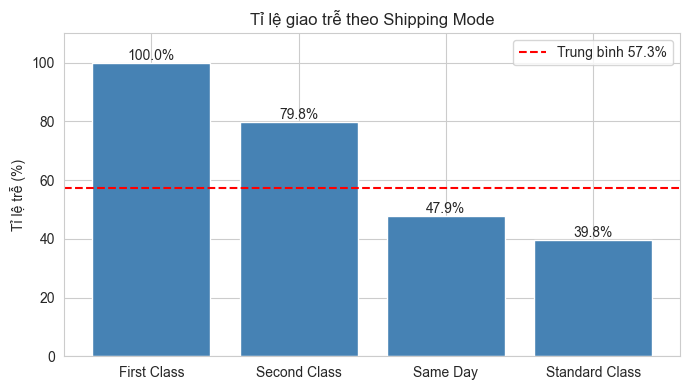

In [32]:
plt.figure(figsize=(7, 4))
plt.bar(ship.index, ship['mean'], color='steelblue')
plt.axhline(ti_le_tb, color='red', linestyle='--', label='Trung bình ' + str(round(ti_le_tb, 1)) + '%')
for i in range(len(ship)):
    plt.text(i, ship['mean'].iloc[i] + 1, str(round(ship['mean'].iloc[i], 1)) + '%', ha='center')
plt.ylabel('Tỉ lệ trễ (%)')
plt.title('Tỉ lệ giao trễ theo Shipping Mode')
plt.ylim(0, 110)
plt.legend()
plt.tight_layout()
plt.savefig('figures_s2/fig05_late_by_shipping_mode.png')
plt.show()

In [33]:
# tỉ lệ trễ theo số ngày giao dự kiến
sched = df.groupby('Days for shipment (scheduled)')['Late_delivery_risk'].agg(['mean', 'count'])
sched['mean'] = sched['mean'] * 100
print(sched)

                                     mean   count
Days for shipment (scheduled)                    
0                               47.928548    9293
1                              100.000000   26513
2                               79.829024   33806
4                               39.769081  103153


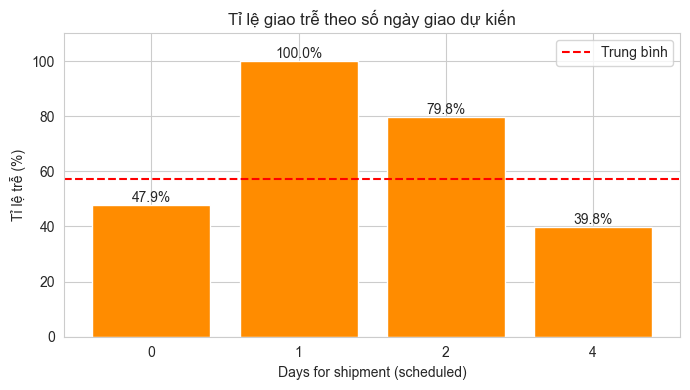

In [34]:
plt.figure(figsize=(7, 4))
plt.bar(sched.index.astype(str), sched['mean'], color='darkorange')
plt.axhline(ti_le_tb, color='red', linestyle='--', label='Trung bình')
for i in range(len(sched)):
    plt.text(i, sched['mean'].iloc[i] + 1, str(round(sched['mean'].iloc[i], 1)) + '%', ha='center')
plt.xlabel('Days for shipment (scheduled)')
plt.ylabel('Tỉ lệ trễ (%)')
plt.title('Tỉ lệ giao trễ theo số ngày giao dự kiến')
plt.ylim(0, 110)
plt.legend()
plt.tight_layout()
plt.savefig('figures_s2/fig06_late_by_scheduled_days.png')
plt.show()

Days for shipment (scheduled)     0      1      2       4
Shipping Mode                                            
First Class                       0  26513      0       0
Same Day                       9293      0      0       0
Second Class                      0      0  33806       0
Standard Class                    0      0      0  103153


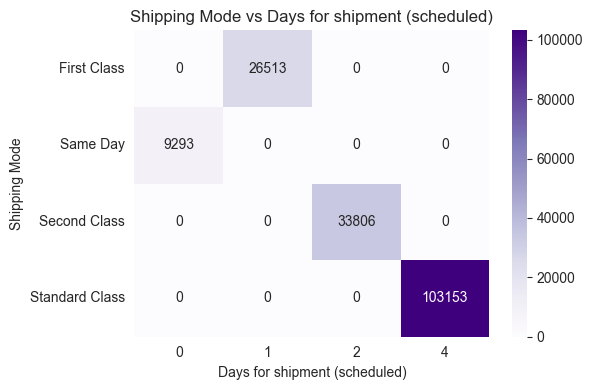

In [35]:
# Shipping Mode và số ngày dự kiến có liên quan với nhau không?
ct3 = pd.crosstab(df['Shipping Mode'], df['Days for shipment (scheduled)'])
print(ct3)
plt.figure(figsize=(6, 4))
sns.heatmap(ct3, annot=True, fmt='d', cmap='Purples')
plt.title('Shipping Mode vs Days for shipment (scheduled)')
plt.tight_layout()
plt.savefig('figures_s2/fig07_shipping_mode_vs_scheduled.png')
plt.show()

In [36]:
# số ngày giao thực tế theo Shipping Mode (cột leakage, chỉ dùng để hiểu dữ liệu, không làm feature)
pd.crosstab(df['Shipping Mode'], df['Days for shipping (real)'])

Days for shipping (real),0,1,2,3,4,5,6
Shipping Mode,,,,,,,
First Class,0,0,26513,0,0,0,0
Same Day,4839,4454,0,0,0,0,0
Second Class,0,0,6819,6759,6759,6772,6697
Standard Class,0,0,20873,20719,20538,20231,20792


**Nhận xét:**
- Sau khi bỏ đơn hủy: `First Class` trễ 100%, `Second Class` 79,8%, `Same Day` 47,9%, `Standard Class` 39,8%.
- Mỗi Shipping Mode gắn với đúng 1 giá trị số ngày dự kiến -> 2 cột này gần như là một (trùng thông tin).
- Đây sẽ là feature quan trọng nhất.

## 6. EDA - Địa lý

In [37]:
market = df.groupby('Market')['Late_delivery_risk'].agg(['mean', 'count'])
market['mean'] = market['mean'] * 100
market = market.sort_values('mean', ascending=False)
print(market)

                   mean  count
Market                        
Europe        57.689748  48090
USCA          57.408535  24627
Pacific Asia  57.375268  39585
LATAM         56.873999  49309
Africa        56.840595  11154


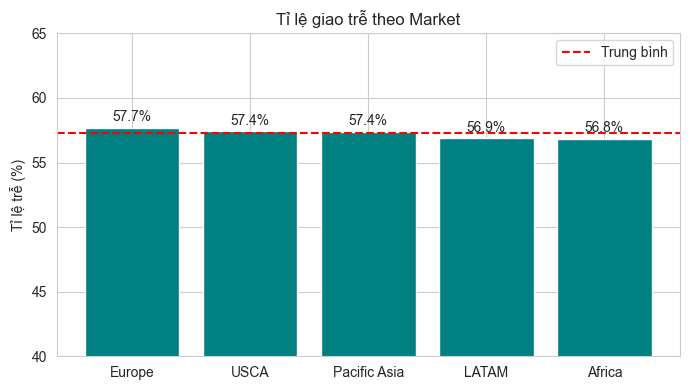

In [38]:
plt.figure(figsize=(7, 4))
plt.bar(market.index, market['mean'], color='teal')
plt.axhline(ti_le_tb, color='red', linestyle='--', label='Trung bình')
for i in range(len(market)):
    plt.text(i, market['mean'].iloc[i] + 0.5, str(round(market['mean'].iloc[i], 1)) + '%', ha='center')
plt.ylabel('Tỉ lệ trễ (%)')
plt.title('Tỉ lệ giao trễ theo Market')
plt.ylim(40, 65)
plt.legend()
plt.tight_layout()
plt.savefig('figures_s2/fig08_late_by_market.png')
plt.show()

In [39]:
region = df.groupby('Order Region')['Late_delivery_risk'].agg(['mean', 'count'])
region['mean'] = region['mean'] * 100
region = region.sort_values('mean')
print(region)

                      mean  count
Order Region                     
Canada           51.598677    907
West Africa      54.690563   3571
Caribbean        55.527607   7951
Southern Africa  56.090909   1100
Northern Europe  56.250000   9408
Oceania          56.323847   9733
Central Asia     56.457565    542
Eastern Asia     56.718772   6973
West of USA      56.787360   7595
Southern Europe  56.799557   9030
North Africa     57.096565   3086
Central America  57.106057  27174
South America    57.184151  14184
US Center        57.526977   5653
Eastern Europe   57.648613   3785
West Asia        57.814132   5746
Southeast Asia   57.979422   9136
East of USA      58.168354   6617
East Africa      58.169568   1781
South Asia       58.350101   7455
South of  USA    58.521401   3855
Western Europe   58.530174  25867
Central Africa   60.148515   1616


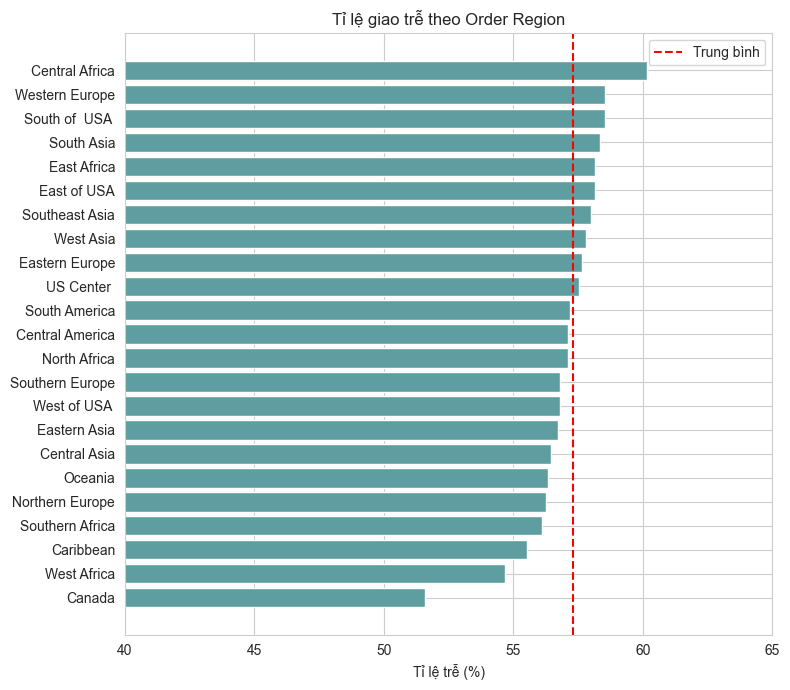

In [40]:
plt.figure(figsize=(8, 7))
plt.barh(region.index, region['mean'], color='cadetblue')
plt.axvline(ti_le_tb, color='red', linestyle='--', label='Trung bình')
plt.xlabel('Tỉ lệ trễ (%)')
plt.title('Tỉ lệ giao trễ theo Order Region')
plt.xlim(40, 65)
plt.legend()
plt.tight_layout()
plt.savefig('figures_s2/fig09_late_by_region.png')
plt.show()

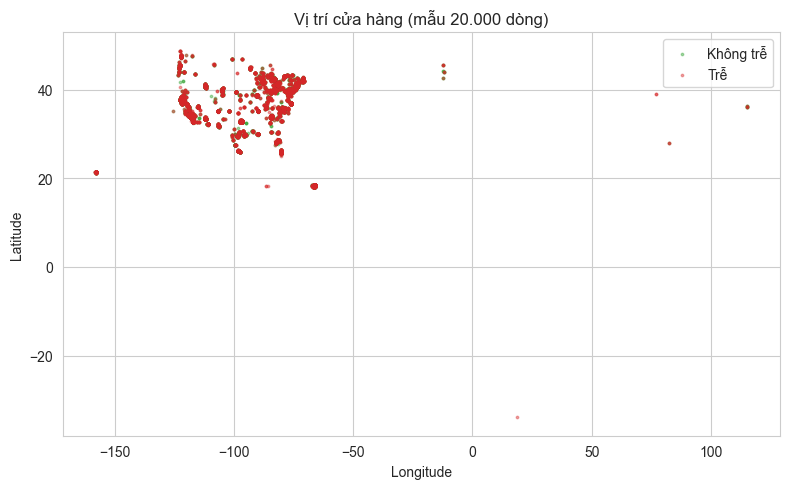

In [41]:
# vị trí cửa hàng (Latitude, Longitude), lấy mẫu 20000 dòng cho nhẹ
sample = df.sample(20000, random_state=42)
plt.figure(figsize=(8, 5))
plt.scatter(sample[sample['Late_delivery_risk'] == 0]['Longitude'], sample[sample['Late_delivery_risk'] == 0]['Latitude'], s=3, alpha=0.4, label='Không trễ', color='tab:green')
plt.scatter(sample[sample['Late_delivery_risk'] == 1]['Longitude'], sample[sample['Late_delivery_risk'] == 1]['Latitude'], s=3, alpha=0.4, label='Trễ', color='tab:red')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Vị trí cửa hàng (mẫu 20.000 dòng)')
plt.legend()
plt.tight_layout()
plt.savefig('figures_s2/fig10_store_location.png')
plt.show()

In [42]:
print(df['Customer Country'].value_counts())

Customer Country
EE. UU.        106425
Puerto Rico     66340
Name: count, dtype: int64


**Nhận xét:**
- Tỉ lệ trễ giữa các Market chỉ từ 56,8% đến 57,7%; giữa các Region từ 51,6% (Canada, 907 dòng) đến 60,1% (Central Africa, 1.616 dòng) -> ảnh hưởng yếu. Hai nhóm ở hai đầu đều ít dòng, nên chưa đủ để kết luận.
- Cửa hàng đều nằm ở Mỹ và Puerto Rico, điểm trễ và không trễ trộn lẫn -> vị trí cửa hàng không phân biệt rõ.

## 7. EDA - Sản phẩm và khách hàng

In [43]:
dept = df.groupby('Department Name')['Late_delivery_risk'].agg(['mean', 'count'])
dept['mean'] = dept['mean'] * 100
dept = dept.sort_values('mean')
print(dept)

                         mean  count
Department Name                     
Discs Shop          56.767885   1943
Fan Shop            57.193947  64033
Apparel             57.215681  46884
Footwear            57.224102  13891
Golf                57.284059  31768
Technology          57.736390   1396
Outdoors            58.001511   9267
Fitness             58.003370   2374
Health and Beauty   58.381503    346
Book Shop           58.567775    391
Pet Shop            61.440678    472


In [44]:
cat = df.groupby('Category Name')['Late_delivery_risk'].agg(['mean', 'count'])
cat['mean'] = cat['mean'] * 100
# chỉ lấy 15 category có nhiều dòng nhất
top_cat = cat.sort_values('count', ascending=False).head(15).sort_values('mean')
print(top_cat)

                           mean  count
Category Name                         
Camping & Hiking      56.905070  13157
Cardio Equipment      56.955139  11948
Men's Footwear        57.005126  21263
Women's Apparel       57.049115  20116
Indoor/Outdoor Games  57.200866  18470
Water Sports          57.237903  14880
Fishing               57.342573  16595
Golf Balls            57.377049   1403
Cleats                57.395594  23514
Shop By Sport         57.612934  10515
Girls' Apparel        58.399296   1137
Golf Gloves           58.503401   1029
Trade-In              58.531317    926
Electronics           58.531746   3024
Accessories           59.752504   1697


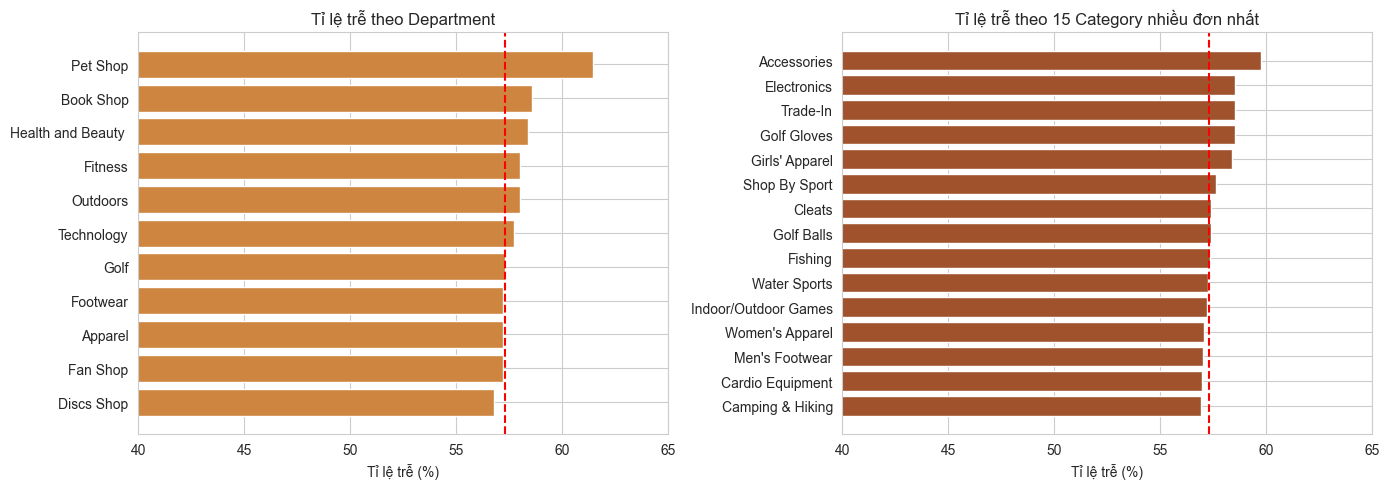

In [45]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].barh(dept.index, dept['mean'], color='peru')
ax[0].axvline(ti_le_tb, color='red', linestyle='--')
ax[0].set_xlim(40, 65)
ax[0].set_title('Tỉ lệ trễ theo Department')
ax[0].set_xlabel('Tỉ lệ trễ (%)')
ax[1].barh(top_cat.index, top_cat['mean'], color='sienna')
ax[1].axvline(ti_le_tb, color='red', linestyle='--')
ax[1].set_xlim(40, 65)
ax[1].set_title('Tỉ lệ trễ theo 15 Category nhiều đơn nhất')
ax[1].set_xlabel('Tỉ lệ trễ (%)')
plt.tight_layout()
plt.savefig('figures_s2/fig11_late_by_product.png')
plt.show()

In [46]:
seg = df.groupby('Customer Segment')['Late_delivery_risk'].mean() * 100
typ = df.groupby('Type')['Late_delivery_risk'].agg(['mean', 'count'])
typ['mean'] = typ['mean'] * 100
print(seg)
print(typ)

Customer Segment
Consumer       57.311563
Corporate      57.078130
Home Office    57.588344
Name: Late_delivery_risk, dtype: float64
               mean  count
Type                      
CASH      56.632341  19616
DEBIT     57.217692  69295
PAYMENT   57.529059  41725
TRANSFER  57.478222  42129


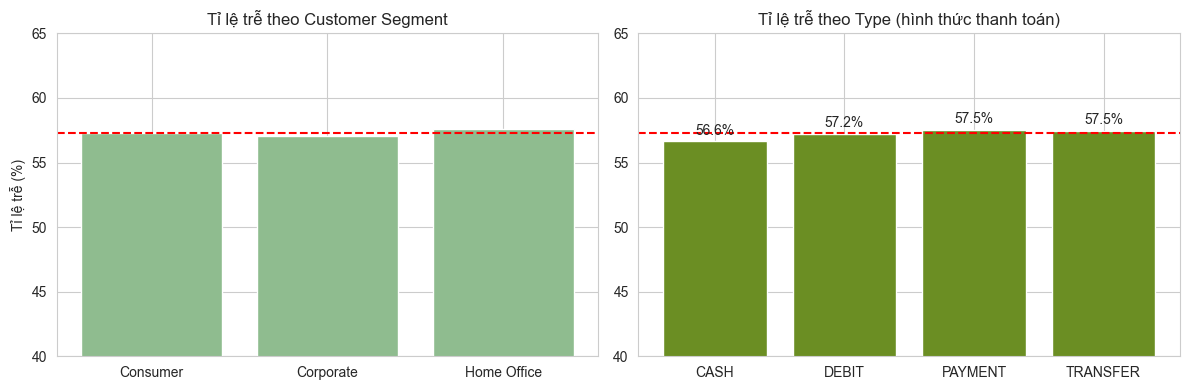

In [47]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(seg.index, seg.values, color='darkseagreen')
ax[0].axhline(ti_le_tb, color='red', linestyle='--')
ax[0].set_ylim(40, 65)
ax[0].set_title('Tỉ lệ trễ theo Customer Segment')
ax[0].set_ylabel('Tỉ lệ trễ (%)')
ax[1].bar(typ.index, typ['mean'], color='olivedrab')
ax[1].axhline(ti_le_tb, color='red', linestyle='--')
ax[1].set_ylim(40, 65)
ax[1].set_title('Tỉ lệ trễ theo Type (hình thức thanh toán)')
for i in range(len(typ)):
    ax[1].text(i, typ['mean'].iloc[i] + 0.5, str(round(typ['mean'].iloc[i], 1)) + '%', ha='center')
plt.tight_layout()
plt.savefig('figures_s2/fig12_late_by_customer_type.png')
plt.show()

In [48]:
# Type = PAYMENT, CASH ... liên quan với Order Status không?
print(pd.crosstab(df['Type'], df['Order Status']))

Order Status  CLOSED  COMPLETE  ON_HOLD  PAYMENT_REVIEW  PENDING  \
Type                                                               
CASH           19616         0        0               0        0   
DEBIT              0     59491     9804               0        0   
PAYMENT            0         0        0            1893        0   
TRANSFER           0         0        0               0    20227   

Order Status  PENDING_PAYMENT  PROCESSING  
Type                                       
CASH                        0           0  
DEBIT                       0           0  
PAYMENT                 39832           0  
TRANSFER                    0       21902  


**Nhận xét:**
- Department, Category, Customer Segment: tỉ lệ trễ gần như bằng trung bình -> ảnh hưởng yếu.
- `Pet Shop` có tỉ lệ trễ cao nhất trong Department (61,4%) nhưng chỉ có 472 dòng, nên chưa đủ để kết luận.
- Sau khi bỏ đơn hủy, `Type = TRANSFER` trễ 57,48%, không còn thấp hơn các loại khác (56,6% đến 57,5%). Khác biệt ~48,5% trước đây là do nhóm này chứa toàn bộ đơn hủy, không phải do vận chuyển.

## 8. EDA - Biến số và tương quan

In [49]:
cot_so = ['Sales', 'Order Item Quantity', 'Product Price', 'Order Item Discount Rate', 'Order Item Profit Ratio', 'Order Profit Per Order']
df[cot_so].describe().T

,count,mean,std,min,25%,50%,75%,max
Sales,172765.0,203.828493,132.392520,9.99000,119.980003,199.919998,299.950012,1999.989990
Order Item Quantity,172765.0,2.127694,1.453663,1.00000,1.000000,1.000000,3.000000,5.000000
Product Price,172765.0,141.278595,139.862956,9.99000,50.000000,59.990002,199.990005,1999.989990
Order Item Discount Rate,172765.0,0.101625,0.070429,0.00000,0.040000,0.090000,0.160000,0.250000
Order Item Profit Ratio,172765.0,0.120801,0.466610,-2.75000,0.080000,0.270000,0.360000,0.500000
Order Profit Per Order,172765.0,22.032360,104.355313,-4274.97998,7.030000,31.520000,64.800003,911.799988


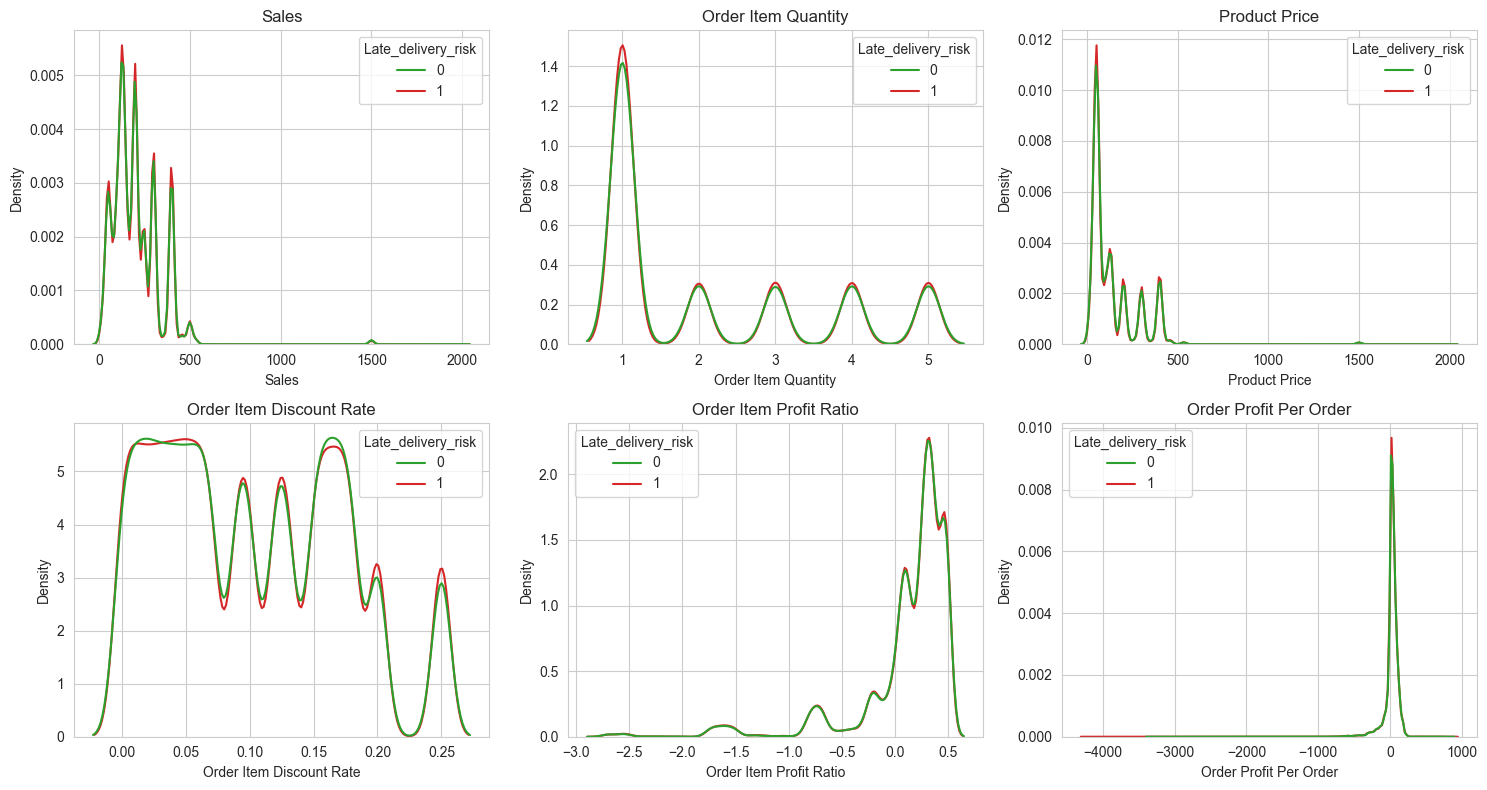

In [50]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
ax = ax.flatten()
for i in range(len(cot_so)):
    col = cot_so[i]
    sns.kdeplot(data=df, x=col, hue='Late_delivery_risk', common_norm=False, ax=ax[i], palette=['tab:green', 'tab:red'])
    ax[i].set_title(col)
plt.tight_layout()
plt.savefig('figures_s2/fig13_numeric_kde.png')
plt.show()

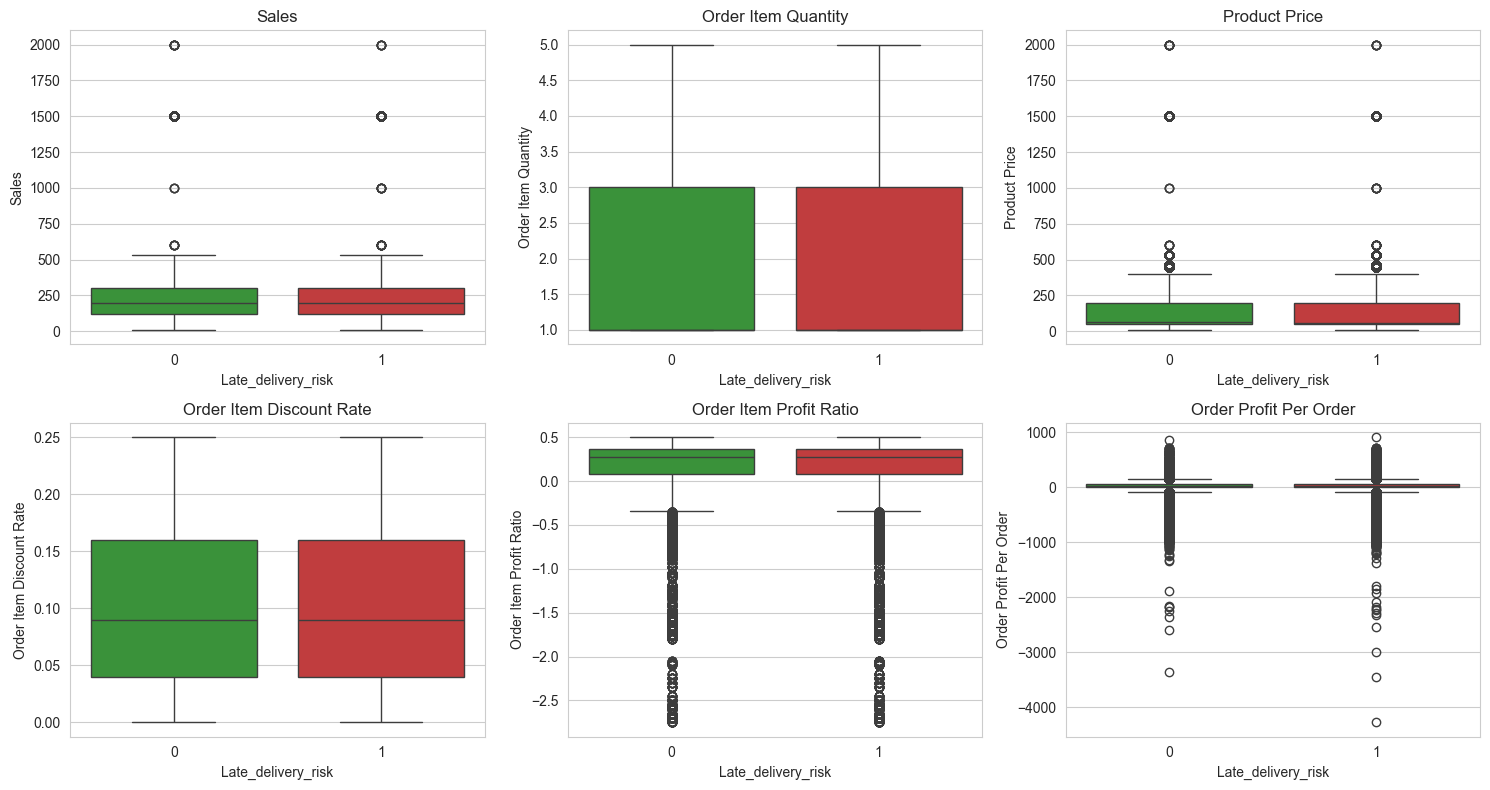

In [51]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
ax = ax.flatten()
for i in range(len(cot_so)):
    col = cot_so[i]
    sns.boxplot(data=df, x='Late_delivery_risk', y=col, ax=ax[i], palette=['tab:green', 'tab:red'])
    ax[i].set_title(col)
plt.tight_layout()
plt.savefig('figures_s2/fig14_numeric_boxplot.png')
plt.show()

In [52]:
# so sánh trung bình 2 nhóm
print(df.groupby('Late_delivery_risk')[cot_so].mean().T)

Late_delivery_risk                 0           1
Sales                     204.478159  203.344163
Order Item Quantity         2.128015    2.127454
Product Price             141.710422  140.956665
Order Item Discount Rate    0.101532    0.101694
Order Item Profit Ratio     0.122324    0.119666
Order Profit Per Order     22.583197   21.621707


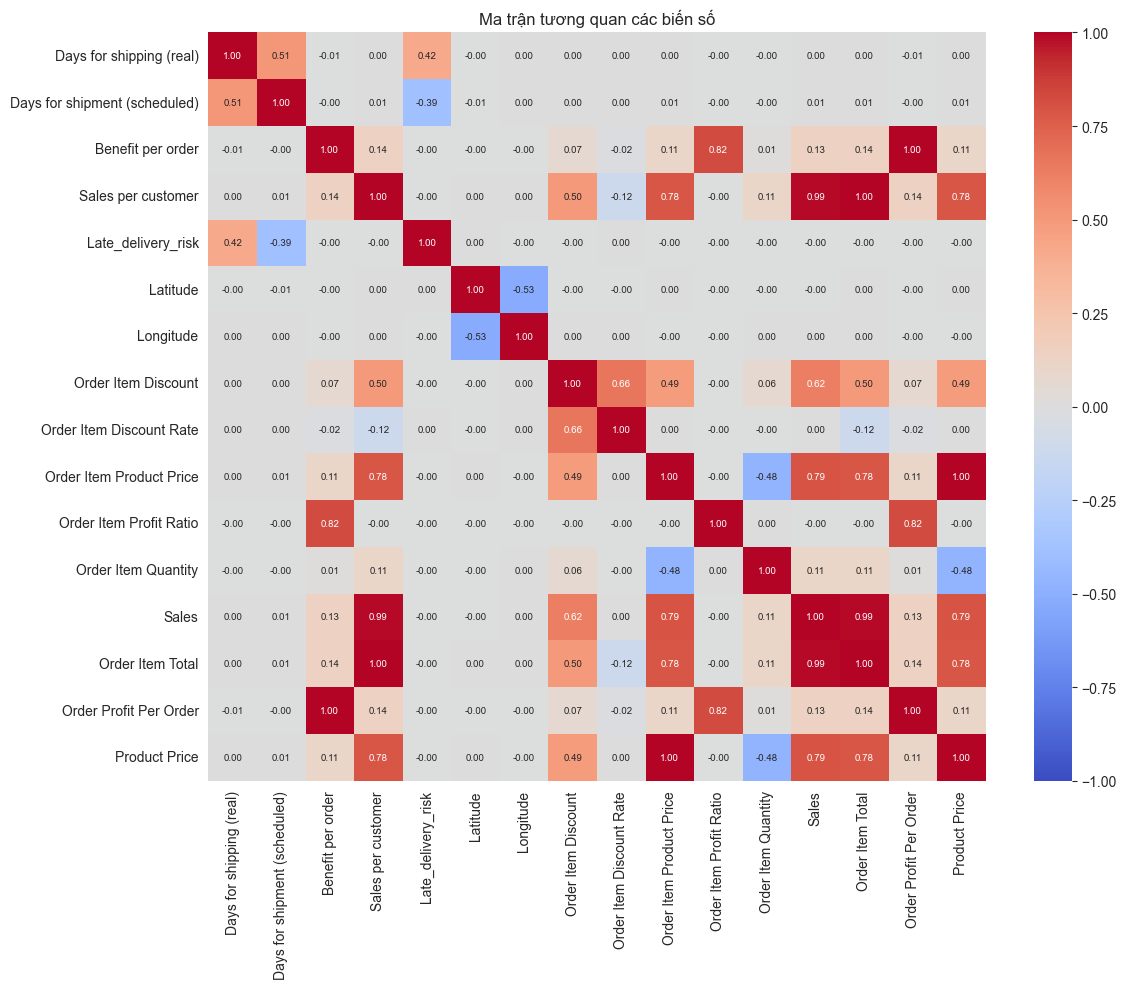

In [53]:
# heatmap tương quan giữa các cột số
cot_so_all = ['Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer',
              'Late_delivery_risk', 'Latitude', 'Longitude', 'Order Item Discount', 'Order Item Discount Rate',
              'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales',
              'Order Item Total', 'Order Profit Per Order', 'Product Price']
corr = df[cot_so_all].corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, annot_kws={'size': 7})
plt.title('Ma trận tương quan các biến số')
plt.tight_layout()
plt.savefig('figures_s2/fig15_correlation.png')
plt.show()

In [54]:
# tìm các cặp cột giống hệt nhau
cap_cot = [('Benefit per order', 'Order Profit Per Order'),
           ('Sales per customer', 'Order Item Total'),
           ('Product Price', 'Order Item Product Price'),
           ('Order Customer Id', 'Customer Id'),
           ('Category Id', 'Product Category Id'),
           ('Product Card Id', 'Order Item Cardprod Id')]
for a, b in cap_cot:
    print(a, '==', b, ':', (df[a] == df[b]).all())

Benefit per order == Order Profit Per Order : True
Sales per customer == Order Item Total : True
Product Price == Order Item Product Price : True
Order Customer Id == Customer Id : True
Category Id == Product Category Id : True
Product Card Id == Order Item Cardprod Id : True


In [55]:
# tương quan với target
print(corr['Late_delivery_risk'].sort_values(ascending=False))

Late_delivery_risk               1.000000
Days for shipping (real)         0.421379
Order Item Discount Rate         0.001136
Latitude                         0.000219
Order Item Quantity             -0.000191
Order Item Discount             -0.000685
Longitude                       -0.002181
Order Item Product Price        -0.002666
Product Price                   -0.002666
Order Item Profit Ratio         -0.002818
Sales                           -0.004237
Sales per customer              -0.004545
Order Item Total                -0.004545
Order Profit Per Order          -0.004558
Benefit per order               -0.004558
Days for shipment (scheduled)   -0.389626
Name: Late_delivery_risk, dtype: float64


**Nhận xét:**
- Phân bố của các biến tiền/giá/số lượng giữa nhóm trễ và không trễ gần như trùng nhau.
- Có nhiều cột **giống hệt nhau** (Benefit per order = Order Profit Per Order, Product Price = Order Item Product Price, ...) và nhiều cột tương quan rất cao (Sales, Order Item Total, Sales per customer) -> chỉ giữ 1 cột.
- Tương quan với target: chỉ `Days for shipping (real)` (leakage) và `Days for shipment (scheduled)` (âm) đáng kể.

## 8b. EDA theo thời gian

Mục này phân tích ở **mức đơn hàng**: mỗi đơn chỉ lấy 1 dòng, vì các dòng trong cùng đơn có chung giờ đặt và chung nhãn. Nếu tính theo dòng, đơn nhiều món sẽ được tính nhiều lần.

Các cột thời gian chỉ tạo trong bảng `don`, nên `df` và mục 9 không thay đổi.

In [56]:
# tạo bảng don: mỗi đơn 1 dòng
don = df.drop_duplicates('Order Id').copy()

# số món của mỗi đơn
so_mon = df.groupby('Order Id').size()
don['so_mon'] = don['Order Id'].map(so_mon)

# tách ngày giờ đặt hàng
don['ngay_dat'] = pd.to_datetime(don['order date (DateOrders)'])
don['month'] = don['ngay_dat'].dt.month
don['dow'] = don['ngay_dat'].dt.dayofweek   # 0 = thứ Hai, 6 = Chủ nhật
don['hour'] = don['ngay_dat'].dt.hour

ti_le_don = don['Late_delivery_risk'].mean() * 100
print('Số đơn:', len(don))
print('Tổng số món có khớp số dòng của df không:', don['so_mon'].sum() == len(df))
print('Tỉ lệ trễ ở mức đơn:', round(ti_le_don, 2), '%')

Số đơn: 62897
Tổng số món có khớp số dòng của df không: True
Tỉ lệ trễ ở mức đơn: 57.31 %


### 8b.1 Giờ đặt hàng theo từng Shipping Mode

In [57]:
# so sánh trước 12h và từ 12h trở đi trong từng Shipping Mode
don['tu_12h'] = don['hour'] >= 12
bang_gio = don.groupby(['Shipping Mode', 'tu_12h'])['Late_delivery_risk'].agg(['mean', 'count'])
bang_gio['mean'] = (bang_gio['mean'] * 100).round(2)
print(bang_gio)

                         mean  count
Shipping Mode  tu_12h               
First Class    False   100.00   4703
               True    100.00   4899
Same Day       False     0.00   1759
               True    100.00   1648
Second Class   False    80.01   6124
               True     79.96   6132
Standard Class False    39.60  18876
               True     40.10  18756


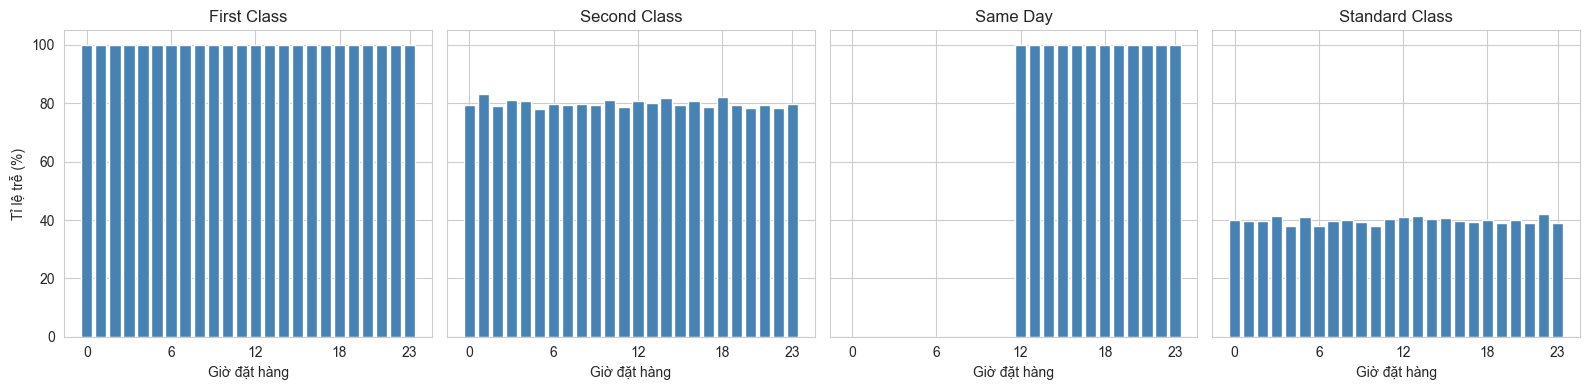

In [58]:
# tỉ lệ trễ theo giờ, mỗi Shipping Mode vẽ một ô riêng
cac_mode = ['First Class', 'Second Class', 'Same Day', 'Standard Class']
fig, ax = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for i in range(len(cac_mode)):
    mode = cac_mode[i]
    tung_gio = don[don['Shipping Mode'] == mode].groupby('hour')['Late_delivery_risk'].mean() * 100
    ax[i].bar(tung_gio.index, tung_gio.values, color='steelblue')
    ax[i].set_title(mode)
    ax[i].set_xlabel('Giờ đặt hàng')
    ax[i].set_xticks([0, 6, 12, 18, 23])
ax[0].set_ylabel('Tỉ lệ trễ (%)')
plt.tight_layout()
plt.savefig('figures_s2/fig16_gio_theo_shipping_mode.png')
plt.show()

**Nhận xét:**
- `Same Day`: đơn đặt trước 12h không trễ (0%, 1.759 đơn), đơn đặt từ 12h đều trễ (100%, 1.648 đơn). Trong nhóm này, giờ đặt hàng quyết định hoàn toàn nhãn.
- `Second Class` (80,01% và 79,96%) và `Standard Class` (39,60% và 40,10%) gần như không đổi theo giờ; `First Class` luôn trễ 100%.

=> Giờ đặt hàng chỉ có tác dụng trong `Same Day`, với mốc chốt 12h. Đây là tương tác giữa hai cột nên không thể đọc từ tỉ lệ trễ theo giờ của toàn bộ dữ liệu. Quy tắc này được tìm trên toàn bộ dữ liệu, nên cần kiểm tra lại trên tập train.

### 8b.2 Tháng và thứ trong tuần

Theo tháng: từ 56.11 đến 57.87 %
Theo thứ: từ 56.9 đến 57.64 %


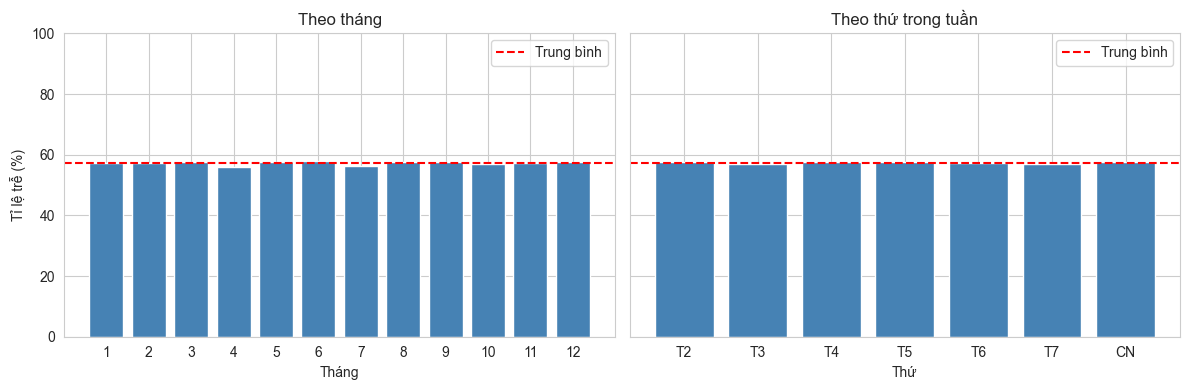

In [59]:
theo_thang = don.groupby('month')['Late_delivery_risk'].mean() * 100
theo_thu = don.groupby('dow')['Late_delivery_risk'].mean() * 100
print('Theo tháng: từ', round(theo_thang.min(), 2), 'đến', round(theo_thang.max(), 2), '%')
print('Theo thứ: từ', round(theo_thu.min(), 2), 'đến', round(theo_thu.max(), 2), '%')

ten_thu = ['T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'CN']
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
ax[0].bar(theo_thang.index, theo_thang.values, color='steelblue')
ax[0].axhline(ti_le_don, color='red', linestyle='--', label='Trung bình')
ax[0].set_title('Theo tháng')
ax[0].set_xlabel('Tháng')
ax[0].set_xticks(range(1, 13))
ax[0].set_ylabel('Tỉ lệ trễ (%)')
ax[0].set_ylim(0, 100)
ax[0].legend()
ax[1].bar(ten_thu, theo_thu.values, color='steelblue')
ax[1].axhline(ti_le_don, color='red', linestyle='--', label='Trung bình')
ax[1].set_title('Theo thứ trong tuần')
ax[1].set_xlabel('Thứ')
ax[1].legend()
plt.tight_layout()
plt.savefig('figures_s2/fig17_thang_va_thu.png')
plt.show()

**Nhận xét:** Tỉ lệ trễ gần như phẳng theo tháng (56,11% đến 57,87%) và theo thứ (56,90% đến 57,64%), nên hai cột này ít có khả năng giúp phân biệt nhãn.

### 8b.3 Dữ liệu thay đổi từ 10/2017

In [60]:
# tính theo từng tháng trong năm
don['thang_nam'] = don['ngay_dat'].dt.to_period('M')
moi_thang = don.groupby('thang_nam').agg(so_don=('Order Id', 'count'),
                                         so_dong=('so_mon', 'sum'),
                                         mon_moi_don=('so_mon', 'mean'))
print(moi_thang.tail(8).round(2))

# so sánh trước và từ 10/2017
tu_10_2017 = don['ngay_dat'] >= '2017-10-01'
print('Món/đơn trước 10/2017:', round(don[~tu_10_2017]['so_mon'].mean(), 2))
print('Món/đơn từ 10/2017:', round(don[tu_10_2017]['so_mon'].mean(), 2))
print('Tỉ lệ đơn 1 món từ 10/2017:', round((don[tu_10_2017]['so_mon'] == 1).mean() * 100, 2), '%')
print('Tỉ lệ trễ trước 10/2017:', round(don[~tu_10_2017]['Late_delivery_risk'].mean() * 100, 2), '%')
print('Tỉ lệ trễ từ 10/2017:', round(don[tu_10_2017]['Late_delivery_risk'].mean() * 100, 2), '%')

           so_don  so_dong  mon_moi_don
thang_nam                              
2017-06      1605     4730         2.95
2017-07      1693     5052         2.98
2017-08      1695     5111         3.02
2017-09      1640     4931         3.01
2017-10      2019     2169         1.07
2017-11      1956     1956         1.00
2017-12      2031     2031         1.00
2018-01      2037     2037         1.00
Món/đơn trước 10/2017: 3.0
Món/đơn từ 10/2017: 1.02
Tỉ lệ đơn 1 món từ 10/2017: 99.23 %
Tỉ lệ trễ trước 10/2017: 57.26 %
Tỉ lệ trễ từ 10/2017: 57.64 %


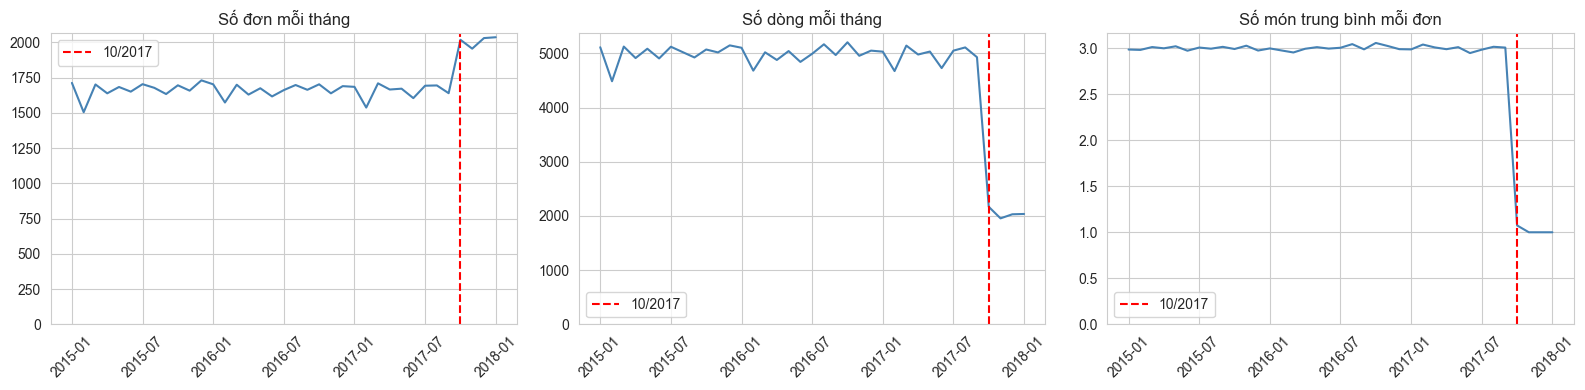

In [61]:
# 3 đại lượng khác đơn vị nên vẽ 3 ô riêng
nhan_thang = moi_thang.index.astype(str)
vi_tri = list(range(len(nhan_thang)))
vi_tri_10_2017 = list(nhan_thang).index('2017-10')
cot_ve = ['so_don', 'so_dong', 'mon_moi_don']
tieu_de = ['Số đơn mỗi tháng', 'Số dòng mỗi tháng', 'Số món trung bình mỗi đơn']

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for i in range(3):
    ax[i].plot(vi_tri, moi_thang[cot_ve[i]].values, color='steelblue')
    ax[i].axvline(vi_tri_10_2017, color='red', linestyle='--', label='10/2017')
    ax[i].set_title(tieu_de[i])
    ax[i].set_xticks(vi_tri[::6])
    ax[i].set_xticklabels(nhan_thang[::6], rotation=45)
    ax[i].set_ylim(bottom=0)
    ax[i].legend()
plt.tight_layout()
plt.savefig('figures_s2/fig18_thay_doi_tu_10_2017.png')
plt.show()

**Nhận xét:**
- Từ 10/2017, số món trung bình mỗi đơn giảm từ 3,00 xuống 1,02, và 99,23% đơn chỉ có 1 món.
- Số dòng mỗi tháng giảm mạnh (4.931 dòng tháng 9 xuống 2.169 dòng tháng 10/2017), nhưng số đơn thực ra tăng (1.640 lên 2.019 đơn). Nhận định cũ "số dòng giảm" chưa đủ: cấu trúc đơn hàng đã thay đổi, không phải đơn hàng giảm.
- Tỉ lệ trễ gần như không đổi (57,26% trước và 57,64% từ 10/2017). Khi chia theo thời gian, tập test sẽ nằm trong giai đoạn có cấu trúc đơn khác, nên cần ghi rõ nếu dùng cách chia này.

## 9. Tiền xử lý dữ liệu

In [62]:
# 1. cột bị leakage
cot_leak = ['Delivery Status', 'Days for shipping (real)', 'shipping date (DateOrders)', 'Order Status']

# 2. cột thông tin cá nhân / định danh / không có ích
cot_dinh_danh = ['Customer Email', 'Customer Password', 'Customer Fname', 'Customer Lname', 'Customer Street',
                 'Customer Zipcode', 'Customer Id', 'Order Customer Id', 'Order Item Id',
                 'Product Image', 'Product Name', 'Product Card Id', 'Order Item Cardprod Id',
                 'Category Id', 'Product Category Id', 'Department Id']

# 3. cột missing nhiều hoặc chỉ có 1 giá trị
cot_missing = ['Product Description', 'Order Zipcode', 'Product Status']

# 4. cột trùng lặp
cot_trung = ['Benefit per order', 'Sales per customer', 'Order Item Total', 'Order Item Product Price', 'Order Item Discount']

# 5. cột có quá nhiều giá trị (high cardinality) - tạm bỏ ở submission 1
cot_nhieu_gia_tri = ['Customer City', 'Customer State', 'Order City', 'Order State', 'Order Country']

# 6. cột không phân biệt được nhãn
cot_it_tin_hieu = ['Customer Country']

# Order Id được giữ lại chỉ để chia train/test, KHÔNG dùng làm feature
cot_bo = cot_leak + cot_dinh_danh + cot_missing + cot_trung + cot_nhieu_gia_tri + cot_it_tin_hieu
print('Số cột bỏ:', len(cot_bo))

data = df.drop(columns=cot_bo)
print('Số cột còn lại:', data.shape[1])
print(data.columns.tolist())

Số cột bỏ: 34
Số cột còn lại: 19
['Type', 'Days for shipment (scheduled)', 'Late_delivery_risk', 'Category Name', 'Customer Segment', 'Department Name', 'Latitude', 'Longitude', 'Market', 'order date (DateOrders)', 'Order Id', 'Order Item Discount Rate', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Profit Per Order', 'Order Region', 'Product Price', 'Shipping Mode']


In [63]:
# lưu bảng danh sách cột bỏ để làm minh chứng
bang_bo = []
for c in cot_leak: bang_bo.append([c, 'Leakage'])
for c in cot_dinh_danh: bang_bo.append([c, 'Định danh / cá nhân'])
for c in cot_missing: bang_bo.append([c, 'Missing nhiều / 1 giá trị'])
for c in cot_trung: bang_bo.append([c, 'Trùng lặp'])
for c in cot_nhieu_gia_tri: bang_bo.append([c, 'Quá nhiều giá trị'])
for c in cot_it_tin_hieu: bang_bo.append([c, 'Tỉ lệ trễ gần như bằng nhau giữa 2 nước'])
bang_bo = pd.DataFrame(bang_bo, columns=['cot', 'ly_do'])
bang_bo.to_csv('results_s2/cac_cot_bi_bo.csv', index=False, encoding='utf-8-sig')
bang_bo

,cot,ly_do
0,Delivery Status,Leakage
1,Days for shipping (real),Leakage
2,shipping date (DateOrders),Leakage
3,Order Status,Leakage
4,Customer Email,Định danh / cá nhân
5,Customer Password,Định danh / cá nhân
6,Customer Fname,Định danh / cá nhân
7,Customer Lname,Định danh / cá nhân
8,Customer Street,Định danh / cá nhân
9,Customer Zipcode,Định danh / cá nhân


In [64]:
data.head()

,Type,Days for shipment (scheduled),Late_delivery_risk,Category Name,Customer Segment,Department Name,Latitude,Longitude,Market,order date (DateOrders),Order Id,Order Item Discount Rate,Order Item Profit Ratio,Order Item Quantity,Sales,Order Profit Per Order,Order Region,Product Price,Shipping Mode
0,DEBIT,4,0,Sporting Goods,Consumer,Fitness,18.251453,-66.037056,Pacific Asia,1/31/2018 22:56,77202,0.04,0.29,1,327.75,91.250000,Southeast Asia,327.75,Standard Class
1,TRANSFER,4,1,Sporting Goods,Consumer,Fitness,18.279451,-66.037064,Pacific Asia,1/13/2018 12:27,75939,0.05,-0.80,1,327.75,-249.089996,South Asia,327.75,Standard Class
2,CASH,4,0,Sporting Goods,Consumer,Fitness,37.292233,-121.881279,Pacific Asia,1/13/2018 12:06,75938,0.06,-0.80,1,327.75,-247.779999,South Asia,327.75,Standard Class
3,DEBIT,4,0,Sporting Goods,Home Office,Fitness,34.125946,-118.291016,Pacific Asia,1/13/2018 11:45,75937,0.07,0.08,1,327.75,22.860001,Oceania,327.75,Standard Class
4,PAYMENT,4,0,Sporting Goods,Corporate,Fitness,18.253769,-66.037048,Pacific Asia,1/13/2018 11:24,75936,0.09,0.45,1,327.75,134.210007,Oceania,327.75,Standard Class


In [65]:
print(data.isnull().sum().sum(), 'giá trị missing còn lại')

0 giá trị missing còn lại


In [66]:
# one-hot encoding cho các cột chữ (cột order date để nguyên dạng ngày tháng)
cot_chu = data.select_dtypes(include='object').columns.tolist()
cot_chu.remove('order date (DateOrders)')
print('Các cột chữ:', cot_chu)
for c in cot_chu:
    print(c, ':', data[c].nunique(), 'giá trị')

Các cột chữ: ['Type', 'Category Name', 'Customer Segment', 'Department Name', 'Market', 'Order Region', 'Shipping Mode']
Type : 4 giá trị
Category Name : 50 giá trị
Customer Segment : 3 giá trị
Department Name : 11 giá trị
Market : 5 giá trị
Order Region : 23 giá trị
Shipping Mode : 4 giá trị


In [67]:
data_encoded = pd.get_dummies(data, columns=cot_chu, drop_first=True)
print('Kích thước sau one-hot:', data_encoded.shape)

Kích thước sau one-hot: (172765, 105)


## 9b. Chia dữ liệu và baseline

**Cách đánh giá:** dùng bảng `don`, mỗi đơn 1 dòng, nên một đơn không thể nằm ở cả train và test. Chia 80% train, 20% test, `random_state=42`, giữ tỉ lệ nhãn bằng `stratify`.

**Baseline** là các mốc so sánh đơn giản: luôn đoán trễ, chỉ dùng Shipping Mode, và Shipping Mode cộng quy tắc 12h của Same Day. Mọi quy tắc đều học trên train rồi mới áp lên test.

In [68]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

train, test = train_test_split(don, test_size=0.2, random_state=42, stratify=don['Late_delivery_risk'])

# kiểm tra không có đơn nào nằm ở cả 2 tập
don_chung = set(train['Order Id']) & set(test['Order Id'])
assert len(don_chung) == 0

print('Số đơn train:', len(train), '- tỉ lệ trễ:', round(train['Late_delivery_risk'].mean() * 100, 2), '%')
print('Số đơn test:', len(test), '- tỉ lệ trễ:', round(test['Late_delivery_risk'].mean() * 100, 2), '%')

Số đơn train: 50317 - tỉ lệ trễ: 57.31 %
Số đơn test: 12580 - tỉ lệ trễ: 57.31 %


In [69]:
# baseline 1: học lớp đa số của từng Shipping Mode trên train
ti_le_mode = train.groupby('Shipping Mode')['Late_delivery_risk'].mean()
lop_da_so = (ti_le_mode >= 0.5).astype(int)
print((ti_le_mode * 100).round(2))
print(lop_da_so)

y_test = test['Late_delivery_risk']
doan_luon_tre = pd.Series(1, index=test.index)
doan_bl1 = test['Shipping Mode'].map(lop_da_so)

Shipping Mode
First Class       100.00
Same Day           48.87
Second Class       79.89
Standard Class     39.86
Name: Late_delivery_risk, dtype: float64
Shipping Mode
First Class       1
Same Day          0
Second Class      1
Standard Class    0
Name: Late_delivery_risk, dtype: int64


In [70]:
# kiểm tra quy tắc 12h của Same Day trên riêng tập train
same_day_train = train[train['Shipping Mode'] == 'Same Day']
kiem_tra_12h = same_day_train.groupby('tu_12h')['Late_delivery_risk'].agg(['mean', 'count'])
print(kiem_tra_12h)

# baseline 2: giống baseline 1, riêng Same Day đoán theo giờ đặt
doan_bl2 = doan_bl1.copy()
la_same_day = test['Shipping Mode'] == 'Same Day'
doan_bl2[la_same_day] = test.loc[la_same_day, 'tu_12h'].astype(int)

        mean  count
tu_12h             
False    0.0   1384
True     1.0   1323


**Nhận xét:** Trên riêng tập train, Same Day vẫn đúng quy tắc: trước 12h trễ 0% (1.384 đơn), từ 12h trễ 100% (1.323 đơn). Vì vậy quy tắc này được áp dụng cho test ở baseline 2.

In [71]:
# hàm tính các chỉ số, lớp dương là "trễ"
def tinh_chi_so(ten, y_that, y_doan):
    return {'cach_lam': ten,
            'accuracy': accuracy_score(y_that, y_doan),
            'precision': precision_score(y_that, y_doan),
            'recall': recall_score(y_that, y_doan),
            'f1': f1_score(y_that, y_doan)}

bang_ket_qua = pd.DataFrame([
    tinh_chi_so('Luôn đoán trễ', y_test, doan_luon_tre),
    tinh_chi_so('Baseline 1: Shipping Mode', y_test, doan_bl1),
    tinh_chi_so('Baseline 2: Shipping Mode + quy tắc 12h', y_test, doan_bl2)
]).round(4)
bang_ket_qua.to_csv('results_s2/ket_qua_baseline.csv', index=False, encoding='utf-8-sig')
bang_ket_qua

,cach_lam,accuracy,precision,recall,f1
0,Luôn đoán trễ,0.5731,0.5731,1.0000,0.7287
1,Baseline 1: Shipping Mode,0.6984,0.8885,0.5417,0.6731
2,Baseline 2: Shipping Mode + quy tắc 12h,0.7242,0.8962,0.5868,0.7092


**Nhận xét:**
- Accuracy tăng dần: luôn đoán trễ 0,5731, baseline 1 là 0,6984, baseline 2 là 0,7242. Chỉ thêm một quy tắc cho Same Day đã tăng khoảng 2,6 điểm.
- Baseline 2 là mốc chính để so với mô hình.
- `Luôn đoán trễ` có F1 cao nhất (0,7287) dù accuracy thấp nhất, vì nó bắt được mọi đơn trễ (recall 1,0). Không nên chỉ nhìn F1.
- Hai baseline có precision cao (khoảng 0,89) nhưng recall thấp (0,54 và 0,59): phần lớn lỗi là bỏ sót đơn trễ, chủ yếu ở `Standard Class`, vì mode này luôn bị đoán là không trễ.

In [72]:
# lỗi của baseline 2 nằm ở Shipping Mode nào? (Late_delivery_risk là nhãn thật của các đơn bị đoán sai)
sai_bl2 = test[doan_bl2 != y_test]
pd.crosstab(sai_bl2['Shipping Mode'], sai_bl2['Late_delivery_risk'])

Late_delivery_risk,0,1
Shipping Mode,,
Second Class,490,0
Standard Class,0,2979


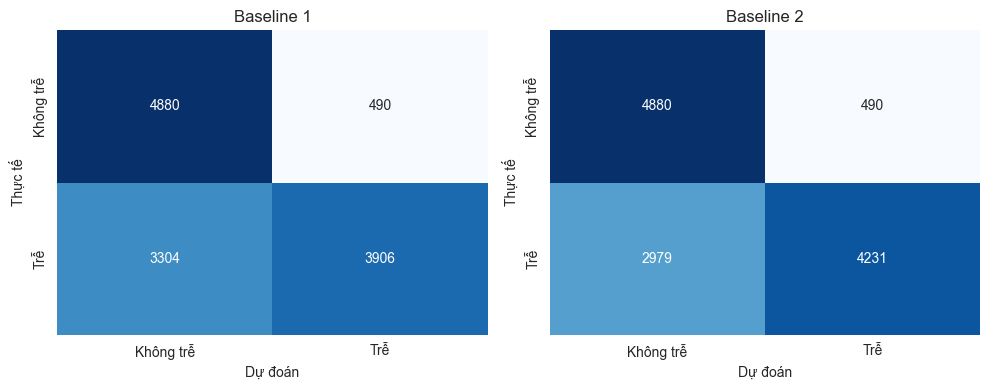

In [73]:
# confusion matrix của 2 baseline
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
nhan = ['Không trễ', 'Trễ']
sns.heatmap(confusion_matrix(y_test, doan_bl1), annot=True, fmt='d', cmap='Blues', ax=ax[0],
            xticklabels=nhan, yticklabels=nhan, cbar=False)
ax[0].set_title('Baseline 1')
sns.heatmap(confusion_matrix(y_test, doan_bl2), annot=True, fmt='d', cmap='Blues', ax=ax[1],
            xticklabels=nhan, yticklabels=nhan, cbar=False)
ax[1].set_title('Baseline 2')
for i in range(2):
    ax[i].set_xlabel('Dự đoán')
    ax[i].set_ylabel('Thực tế')
plt.tight_layout()
plt.savefig('figures_s2/fig19_confusion_baseline.png')
plt.show()

In [74]:
# đo mức dao động: lặp lại với 5 cách chia, KHÔNG dùng để chọn cách chia đẹp nhất
dao_dong = []
for so in [0, 1, 2, 3, 42]:
    tr, te = train_test_split(don, test_size=0.2, random_state=so, stratify=don['Late_delivery_risk'])
    lop = (tr.groupby('Shipping Mode')['Late_delivery_risk'].mean() >= 0.5).astype(int)
    doan1 = te['Shipping Mode'].map(lop)
    doan2 = doan1.copy()
    sd = te['Shipping Mode'] == 'Same Day'
    doan2[sd] = te.loc[sd, 'tu_12h'].astype(int)
    dao_dong.append([so, accuracy_score(te['Late_delivery_risk'], doan1), accuracy_score(te['Late_delivery_risk'], doan2)])

dao_dong = pd.DataFrame(dao_dong, columns=['random_state', 'baseline_1', 'baseline_2']).round(4)
print(dao_dong)
print('Chênh giữa lớn nhất và nhỏ nhất:')
print((dao_dong[['baseline_1', 'baseline_2']].max() - dao_dong[['baseline_1', 'baseline_2']].min()).round(4))

   random_state  baseline_1  baseline_2
0             0      0.6921      0.7178
1             1      0.6998      0.7250
2             2      0.6964      0.7240
3             3      0.6940      0.7210
4            42      0.6984      0.7242
Chênh giữa lớn nhất và nhỏ nhất:
baseline_1    0.0077
baseline_2    0.0072
dtype: float64


**Nhận xét:** Chỉ đổi cách chia, accuracy đã dao động khoảng 0,7 điểm: baseline 1 từ 0,6921 đến 0,6998, baseline 2 từ 0,7178 đến 0,7250. `random_state=42` nằm ở phía cao của khoảng này, nên báo cáo cần nêu cả khoảng dao động. Mức chênh giữa hai cách làm nhỏ hơn khoảng 0,7 điểm chưa đủ để kết luận cách nào tốt hơn.

In [75]:
# ước tính sai số của accuracy khi đổi kích thước tập test, dùng công thức căn(p(1-p)/n)
p = accuracy_score(y_test, doan_bl2)
for ts in [0.1, 0.2, 0.3]:
    n = int(np.ceil(len(don) * ts))   # train_test_split làm tròn lên số đơn test
    sai_so = np.sqrt(p * (1 - p) / n) * 100
    print('test_size', ts, '- số đơn test:', n, '- số đơn train:', len(don) - n,
          '- sai số chuẩn:', round(sai_so, 2), 'điểm - khoảng 95%: ±', round(1.96 * sai_so, 2), 'điểm')

test_size 0.1 - số đơn test: 6290 - số đơn train: 56607 - sai số chuẩn: 0.56 điểm - khoảng 95%: ± 1.1 điểm
test_size 0.2 - số đơn test: 12580 - số đơn train: 50317 - sai số chuẩn: 0.4 điểm - khoảng 95%: ± 0.78 điểm
test_size 0.3 - số đơn test: 18870 - số đơn train: 44027 - sai số chuẩn: 0.33 điểm - khoảng 95%: ± 0.64 điểm


**Nhận xét:** Với `test_size=0.2`, sai số 95% của accuracy khoảng ±0,78 điểm, phù hợp với mức dao động 0,7 điểm khi đổi cách chia. Tăng lên 0,3 chỉ giảm sai số thêm khoảng 0,14 điểm nhưng mất thêm khoảng 6.300 đơn train.

In [76]:
# đối chiếu với số của mentor: Shipping Mode ở mức dòng, trên toàn bộ dữ liệu sạch, chưa chia train/test
lop_toan_bo = (df.groupby('Shipping Mode')['Late_delivery_risk'].mean() >= 0.5).astype(int)
doan_muc_dong = df['Shipping Mode'].map(lop_toan_bo)
print('Accuracy mức dòng:', round(accuracy_score(df['Late_delivery_risk'], doan_muc_dong), 4))

Accuracy mức dòng: 0.6973


**Nhận xét:** Ở mức dòng, trên toàn bộ dữ liệu sạch và chưa chia train/test, baseline Shipping Mode đạt 0,6973, gần với mức ~69,5% của mentor. Số này khác mức đánh giá chính của bài (mức đơn, trên test) nên chỉ dùng để đối chiếu.

## 9c. Mô hình

**Feature:** `Shipping Mode`, `hour`, `dow`, `month`, `Market`, `Order Region`, `Type`, `Customer Segment`. Đây đều là thông tin biết được lúc đặt hàng và là thông tin của cả đơn.

**Không dùng:** 4 cột leakage, `Order Id`, nhóm sản phẩm (thông tin của từng món, 1 đơn có thể có nhiều nhóm) và `Days for shipment (scheduled)` (trùng hoàn toàn với Shipping Mode).

Tham số được đặt trước, không chỉnh theo tập test.

In [77]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

# nhóm sản phẩm là thông tin của từng món: bao nhiêu % đơn có nhiều hơn 1 nhóm?
so_nhom = df.groupby('Order Id')['Department Name'].nunique()
print('Tỉ lệ đơn có nhiều hơn 1 Department Name:', round((so_nhom > 1).mean() * 100, 1), '%')

cot_chu_mh = ['Shipping Mode', 'Market', 'Order Region', 'Type', 'Customer Segment']
cot_so_mh = ['hour', 'dow', 'month']

X = pd.get_dummies(don[cot_chu_mh + cot_so_mh], columns=cot_chu_mh, dtype=int)

# feature tương tác cho Logistic Regression: đơn Same Day đặt từ 12h
X_tuong_tac = X.copy()
X_tuong_tac['same_day_tu_12h'] = ((don['Shipping Mode'] == 'Same Day') & (don['tu_12h'])).astype(int)

print('Số feature:', X.shape[1], '- có tương tác:', X_tuong_tac.shape[1])
assert 'Order Id' not in X.columns

Tỉ lệ đơn có nhiều hơn 1 Department Name: 63.1 %


Số feature: 42 - có tương tác: 43


In [78]:
# hàm train 1 mô hình trên 1 cách chia, trả về xác suất dự đoán
def chay_mo_hinh(ten, tr, te):
    y_tr = tr['Late_delivery_risk']
    if ten == 'Decision Tree (max_depth=6)':
        X_tr, X_te = X.loc[tr.index], X.loc[te.index]
        mo_hinh = DecisionTreeClassifier(max_depth=6, random_state=42)
    else:
        bang_x = X_tuong_tac if ten == 'Logistic Regression + tương tác' else X
        chuan_hoa = StandardScaler()
        X_tr = chuan_hoa.fit_transform(bang_x.loc[tr.index])   # chỉ học chuẩn hóa trên train
        X_te = chuan_hoa.transform(bang_x.loc[te.index])
        mo_hinh = LogisticRegression(max_iter=2000)
    mo_hinh.fit(X_tr, y_tr)
    return mo_hinh, mo_hinh.predict_proba(X_tr)[:, 1], mo_hinh.predict_proba(X_te)[:, 1]

cac_mo_hinh = ['Logistic Regression', 'Logistic Regression + tương tác', 'Decision Tree (max_depth=6)']
xs_test = {}
mo_hinh_da_hoc = {}
ket_qua_mh = []
for ten in cac_mo_hinh:
    mo_hinh, p_train, p_test = chay_mo_hinh(ten, train, test)
    xs_test[ten] = p_test
    mo_hinh_da_hoc[ten] = mo_hinh
    dong = tinh_chi_so(ten, y_test, (p_test >= 0.5).astype(int))
    dong['roc_auc'] = roc_auc_score(y_test, p_test)
    dong['accuracy_train'] = accuracy_score(train['Late_delivery_risk'], (p_train >= 0.5).astype(int))
    ket_qua_mh.append(dong)

bang_mo_hinh = pd.concat([bang_ket_qua, pd.DataFrame(ket_qua_mh)], ignore_index=True).round(4)
bang_mo_hinh.to_csv('results_s2/ket_qua_mo_hinh.csv', index=False, encoding='utf-8-sig')

# điểm dừng: accuracy quá cao thì phải rà lại leakage
print('Accuracy cao nhất của mô hình:', bang_mo_hinh['accuracy'].iloc[3:].max())
bang_mo_hinh

Accuracy cao nhất của mô hình: 0.7242


,cach_lam,accuracy,precision,recall,f1,roc_auc,accuracy_train
0,Luôn đoán trễ,0.5731,0.5731,1.0000,0.7287,NaN,NaN
1,Baseline 1: Shipping Mode,0.6984,0.8885,0.5417,0.6731,NaN,NaN
2,Baseline 2: Shipping Mode + quy tắc 12h,0.7242,0.8962,0.5868,0.7092,NaN,NaN
3,Logistic Regression,0.7177,0.8934,0.5763,0.7006,0.7435,0.7163
4,Logistic Regression + tương tác,0.7242,0.8962,0.5868,0.7092,0.7778,0.7222
5,Decision Tree (max_depth=6),0.7238,0.8931,0.5885,0.7095,0.7777,0.7227


**Nhận xét:**
- Không mô hình nào vượt baseline 2 (0,7242). Accuracy cao nhất cũng là 0,7242, thấp hơn mức 0,75 cần rà leakage.
- Logistic Regression không có feature tương tác đạt 0,7177, thấp hơn baseline 2, vì nó không tự học được quy tắc "Same Day và từ 12h". Thêm feature này thì accuracy tăng lên 0,7242 và ROC-AUC từ 0,7435 lên 0,7778.
- Decision Tree tự học được tương tác đó mà không cần tạo feature riêng: accuracy 0,7238, ROC-AUC 0,7777.
- Accuracy train và test gần nhau (0,7227 và 0,7238 với Decision Tree), nên không thấy overfit. Có dấu hiệu underfit hoặc dữ liệu không còn thông tin để học thêm.

Mô hình có accuracy cao nhất: Logistic Regression + tương tác


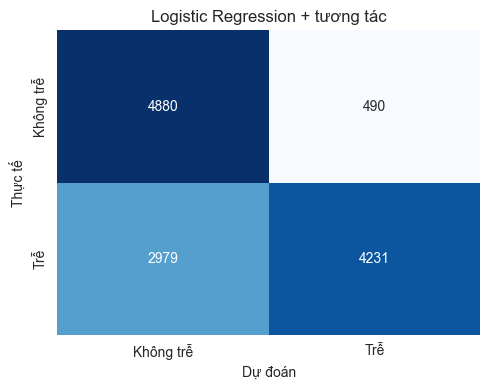

In [79]:
# confusion matrix của mô hình có accuracy cao nhất trên test
ten_tot_nhat = bang_mo_hinh.iloc[3:].sort_values('accuracy', ascending=False)['cach_lam'].iloc[0]
print('Mô hình có accuracy cao nhất:', ten_tot_nhat)

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, (xs_test[ten_tot_nhat] >= 0.5).astype(int)), annot=True, fmt='d', cmap='Blues',
            xticklabels=nhan, yticklabels=nhan, cbar=False)
plt.title(ten_tot_nhat)
plt.xlabel('Dự đoán')
plt.ylabel('Thực tế')
plt.tight_layout()
plt.savefig('figures_s2/fig20_confusion_mo_hinh.png')
plt.show()

In [80]:
# Decision Tree dùng feature nào nhiều nhất?
do_quan_trong = pd.Series(mo_hinh_da_hoc['Decision Tree (max_depth=6)'].feature_importances_, index=X.columns)
print(do_quan_trong.sort_values(ascending=False).head(6).round(4))

Shipping Mode_Standard Class    0.6463
hour                            0.1935
Shipping Mode_Same Day          0.1051
Shipping Mode_Second Class      0.0491
dow                             0.0011
Customer Segment_Consumer       0.0011
dtype: float64


**Nhận xét:** Decision Tree gần như chỉ dùng Shipping Mode và `hour`. Các feature khác có độ quan trọng rất nhỏ, phù hợp với EDA: địa lý, loại thanh toán và phân khúc khách hàng gần như không giúp phân biệt nhãn.

In [81]:
# so sánh trên cùng 5 cách chia ở mục 9b
so_sanh = []
for so in [0, 1, 2, 3, 42]:
    tr, te = train_test_split(don, test_size=0.2, random_state=so, stratify=don['Late_delivery_risk'])
    lop = (tr.groupby('Shipping Mode')['Late_delivery_risk'].mean() >= 0.5).astype(int)
    doan2 = te['Shipping Mode'].map(lop)
    sd = te['Shipping Mode'] == 'Same Day'
    doan2[sd] = te.loc[sd, 'tu_12h'].astype(int)
    dong = {'random_state': so, 'Baseline 2': accuracy_score(te['Late_delivery_risk'], doan2)}
    for ten in cac_mo_hinh:
        _, _, p_te = chay_mo_hinh(ten, tr, te)
        dong[ten] = accuracy_score(te['Late_delivery_risk'], (p_te >= 0.5).astype(int))
    so_sanh.append(dong)

so_sanh = pd.DataFrame(so_sanh).round(4)
so_sanh.to_csv('results_s2/so_sanh_5_cach_chia.csv', index=False, encoding='utf-8-sig')
print(so_sanh.T)
print('Trung bình:')
print(so_sanh.drop(columns='random_state').mean().round(4))

                                      0       1       2       3        4
random_state                     0.0000  1.0000  2.0000  3.0000  42.0000
Baseline 2                       0.7178  0.7250  0.7240  0.7210   0.7242
Logistic Regression              0.7115  0.7196  0.7140  0.7119   0.7177
Logistic Regression + tương tác  0.7178  0.7250  0.7240  0.7210   0.7242
Decision Tree (max_depth=6)      0.7167  0.7251  0.7229  0.7199   0.7238
Trung bình:
Baseline 2                         0.7224
Logistic Regression                0.7149
Logistic Regression + tương tác    0.7224
Decision Tree (max_depth=6)        0.7217
dtype: float64


**Nhận xét:** Trên 5 cách chia, trung bình accuracy là: baseline 2 0,7224, Logistic Regression + tương tác 0,7224, Decision Tree 0,7217, Logistic Regression 0,7149. Logistic Regression + tương tác cho accuracy bằng đúng baseline 2 ở cả 5 lần, còn Decision Tree chênh rất ít.

=> Với các feature này, mô hình chỉ học lại quy tắc đơn giản, chưa tạo thêm giá trị so với baseline 2. Mức chênh giữa baseline 2 và hai mô hình tốt nhất nằm trong mức dao động, nên không kết luận được mô hình nào tốt hơn.

## 10. Tổng kết Submission 2

- Bài toán: **binary classification**, target `Late_delivery_risk`. Mô hình chỉ áp dụng cho **đơn không bị hủy**.
- Làm sạch: bỏ 7.754 dòng đơn hủy, còn 172.765 dòng và 62.897 đơn. Tỉ lệ trễ 57,29% ở mức dòng và 57,31% ở mức đơn. Luật `real > scheduled` khớp nhãn 100%.
- EDA: Shipping Mode mạnh nhất (First Class trễ 100%, Second Class 79,8%, Same Day 47,9%, Standard Class 39,8%). `Type = TRANSFER` không còn khác biệt sau khi bỏ đơn hủy.
- EDA thời gian: giờ đặt chỉ có tác dụng trong Same Day (trước 12h trễ 0%, từ 12h trễ 100%). Tháng và thứ gần như phẳng. Từ 10/2017 số món mỗi đơn giảm từ 3,00 xuống 1,02.
- Đánh giá ở mức đơn, chia 80/20, `random_state=42`, có `stratify`.
- Kết quả trên test: luôn đoán trễ 0,5731; baseline 1 là 0,6984; baseline 2 là 0,7242; mô hình tốt nhất 0,7242. Trung bình 5 cách chia: baseline 2 và Logistic Regression + tương tác đều 0,7224.
- Kết luận: với các feature hiện có, mô hình chỉ học lại quy tắc Shipping Mode + 12h, chưa tạo thêm giá trị so với baseline 2.

**Hướng làm tiếp:**
- Chia theo thời gian để kiểm tra độ bền, lưu ý cấu trúc đơn đổi từ 10/2017.
- Tìm thêm feature cho Second Class và Standard Class, vì toàn bộ lỗi của baseline 2 nằm ở hai nhóm này.
- Thử thêm mô hình khác sau khi có feature mới.
